In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [2]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks



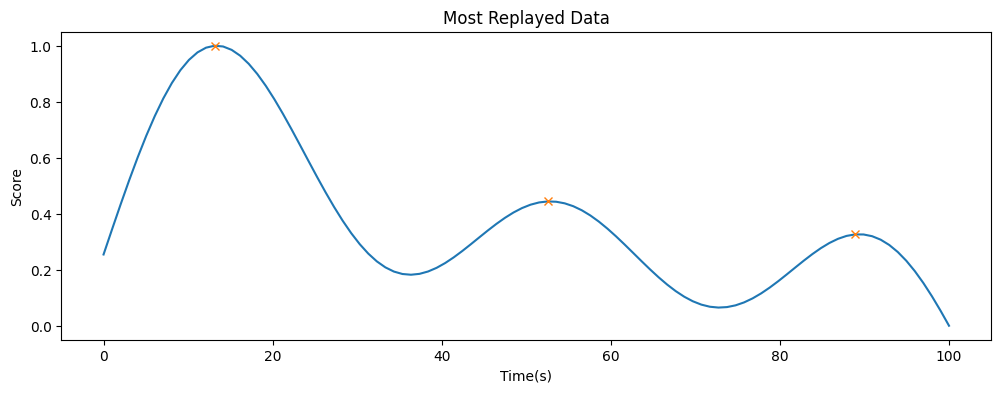

In [3]:
x = np.linspace(0, 100, 100)
y = np.sin(x * 0.05) + np.sin(2 * x * 0.05) + np.sin(3 * x * 0.05)  # Adjust the frequency to fit within 0 to 6 range

# Normalize y values to be between 0 and 1
y_normalized = (y - np.min(y)) / (np.max(y) - np.min(y))
peaks, _ = find_peaks(y_normalized, prominence = 0.1)


# Plot the normalized points for x up to 100
plt.figure(figsize=(12, 4))

plt.plot(x, y_normalized)
plt.plot(x[peaks], y_normalized[peaks], "x", label='Peaks')  # Mark the peaks

plt.title('Most Replayed Data')
plt.xlabel('Time(s)')
plt.ylabel('Score')
plt.show()

In [4]:
peaks

array([13, 52, 88], dtype=int64)

In [5]:
smoothed_intensity_scores = y_normalized

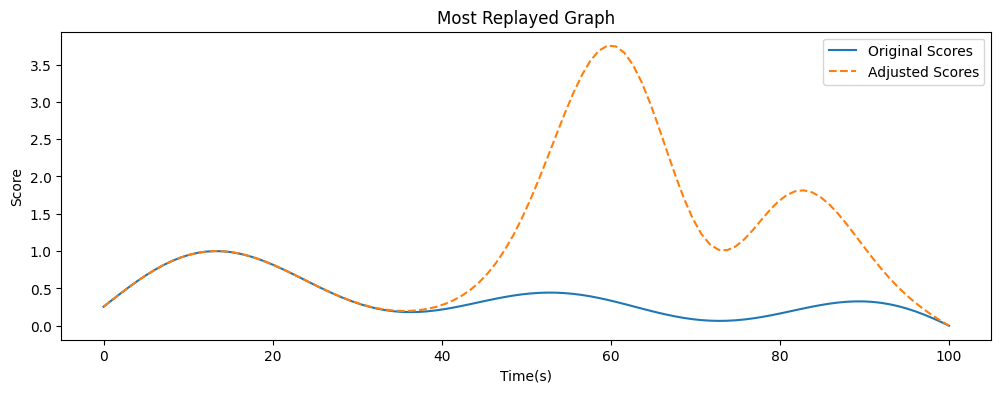

In [6]:
# 특정 점 선택
start_interval = 65  # 구간의 시작점
end_interval = 75 
sigma = 10  # 가우시안 분포의 표준편차

# 가장 높은 피크 찾기
interval_scores = smoothed_intensity_scores[start_interval:end_interval+1]
average_importance_score = np.min(interval_scores) # 최솟값!!
# average_importance_score = np.mean(interval_scores)
max_peak_value = max(smoothed_intensity_scores)
C = max_peak_value/average_importance_score

# 가우시안 분포 생성 (구간 전후로 증가하고 감소)
gaussian = 0
for i in range(start_interval, end_interval):
    gaussian += np.exp(-((x - i) ** 2) / (2 * sigma ** 2))

# 가우시안 분포의 최대 값을 조정
gaussian = gaussian / gaussian.max() * (C)

# 구간 내 상수 값 적용
adjusted_scores = smoothed_intensity_scores.copy()
adjusted_scores*= (1 + gaussian)

# 그래프 그리기
plt.figure(figsize=(12, 4))
plt.plot(x, smoothed_intensity_scores, label='Original Scores')
plt.plot(x, adjusted_scores, label='Adjusted Scores', linestyle='--')
# plt.plot(x[peaks], adjusted_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph')
plt.xlabel('Time(s)')
plt.ylabel('Score')
plt.legend()
# plt.show()

In [28]:
scores = adjusted_scores


In [29]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [30]:
total_time = 50

In [31]:
max_t = total_time

In [32]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [33]:
len(states)

100

In [34]:
min_time = 2

In [35]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [36]:
set_next_states(states, min_time, max_t)

In [37]:
states[0][0].next_states

[(1, 1)]

In [38]:
import numpy as np

def select_optimal_points(states, num_points=3):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 2), -1, dtype=int)  # 추적 테이블 수정

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                # **수정된 부분: 유효한 상태인지 확인**
                if dp[i, t, k - 1] != -np.inf:  # 유효한 상태인 경우에만 업데이트
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t)

    # 최대 점수와 마지막 인덱스 찾기
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        selected_points.append(max_index[0])
        max_index = tuple(trace[max_index[0], max_index[1], k])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [39]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        # if i == 162 and t == 7 and k == num_points:
                        #     pdb.set_trace()  
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace


In [40]:
def find_path(states, dp, trace, num_points=30):

    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

In [41]:
dp, trace = DP(states, num_points=total_time) 
selected_points, max_score = find_path(states, dp, trace, num_points=total_time)


In [42]:
selected_points

[10,
 11,
 12,
 13,
 14,
 15,
 16,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89]

In [43]:
max_score

94.6949594956903

In [44]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [45]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [46]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [47]:
for group in grouped_points:
    group.append(group[-1]+1)

C:\Users\vml_sub\AppData\Local\Temp\ipykernel_290416\285343870.py:33: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


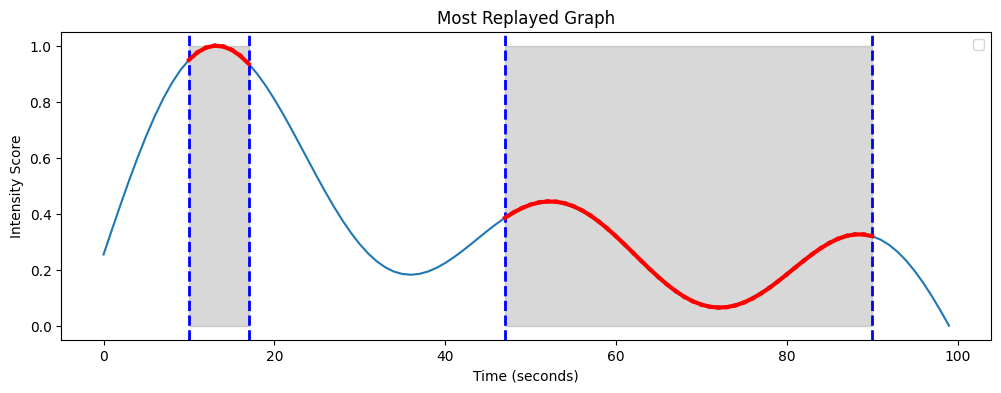

In [52]:
# 그래프 그리기
# 그래프 그리기
plt.figure(figsize=(12, 4))

plt.plot(smoothed_intensity_scores,)
# plt.scatter(selected_points, selected_smoothed_scores, color='r', label='Selected Points')

# 연속된 점들의 그룹 크기를 그래프에 표시
# for group, size in zip(grouped_points, group_sizes):
#     mid_point = group[len(group) // 2]
#     plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=25, ha='center')

# for group in grouped_points:
#     for i in range(len(group) -1 ):
#         plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=3)


for group in grouped_points:
    start = group[0]
    end = group[-1]
    plt.axvline(x=start, color='b', linestyle='--', linewidth=2)
    plt.axvline(x=end, color='b', linestyle='--', linewidth=2)
    plt.fill_betweenx(y=[0, 1], x1=start, x2=end, color='grey', alpha=0.3)  # Shaded area
    for i in range(len(group) - 1):
        plt.plot([group[i], group[i + 1]], 
                 [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], 
                 color='r', linewidth=3)

plt.title('Most Replayed Graph')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.legend()
plt.show()